---
title: "L7-09 · A research protocol from question to result"
short_title: "A research protocol from question to result"
subtitle: "A result means what its protocol lets it mean: the false-positive rate is a property of the whole plan, including when you stop, so the plan has to exist before the data do."
description: "Write a falsifiable, preregistered study protocol for a quantum or quantum causal estimation problem, with an identified estimand, a sample size computed exactly, a stopping rule whose error rate is proved, and an analysis plan fixed before the data."
tags: [level-7, coursebook]
---

(lesson-l7-09)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 120 minutes  
**Big idea.** A result means what its protocol lets it mean: the false-positive rate is a property of the whole plan, including when you stop, so the plan has to exist before the data do.  
**Before this lesson.** [L6-10](#lesson-l6-10), [L7-05](#lesson-l7-05), [L7-06](#lesson-l7-06), [L7-08](#lesson-l7-08)  
**Lab.** [Noise and quantum channels](../../labs/07-noise-channels.ipynb)
:::

## What you will be able to do

- Write the nine stations of a protocol (question, estimand, identification, design, sample size, stopping rule, analysis plan, robustness, report) for a stated estimation problem, and compute an exact binomial sample size.
- Prove that repeated significance testing on accumulating data inflates the false-positive rate, compute that rate for $K$ looks, and prove the validity of a Bonferroni (alpha-spending) rule and of a likelihood-ratio rule through Ville's inequality.
- Run a simulated two-qubit causal study end to end: derive the identified effect, test it as planned, and separate the established result from numerical evidence and interpretation.

## Why this matters

Suppose a group measures a qubit channel, computes a p-value after every 50 shots, and stops the first time it falls below 0.05. Every individual test is correct. Yet when the true noise parameter is exactly at the specification, this group will announce that the device is out of specification about 0.176 of the time if it allows 20 looks, more than three times the advertised 5%. If it watched continuously and had unlimited shots, it would eventually announce it with probability one. Nothing in the final report would reveal this unless the stopping rule were written down.

The same failure has many disguises: trying ten preprocessing choices and reporting the best, choosing the baseline after seeing the results, dropping the run that looked like a calibration fault. At the research frontier, where effects are small, shots are expensive and simulations can be rerun at will, these choices decide whether a claimed quantum or causal effect is real. This lesson treats the protocol as a mathematical object: each of its stations has a precise content, and the error guarantees you report are theorems about the whole protocol, not about the last formula you applied.

:::{dropdown} Key terms

**Preregistered protocol**
: A dated document, fixed before any outcome data are seen, that states the question, estimand, identification assumptions, design, sample size, stopping rule, analysis plan and robustness checks.

**Estimand**
: The quantity the study is about, defined inside a model before any estimator is chosen, for example the depolarizing parameter $p$ or an average causal effect.

**Stopping rule**
: The rule, fixed in advance, that says after which observations data collection ends; part of the test, because the error rate depends on it.

**Optional stopping**
: Looking at the data repeatedly and stopping when the result looks significant; with a fixed per-look threshold it inflates the false-positive rate.

**Alpha spending**
: Splitting the total level $\alpha$ into amounts $\alpha_1, \dots, \alpha_K$ with $\sum_j \alpha_j \le \alpha$, one for each look; Bonferroni is the equal split.

**Anytime-valid test**
: A test whose false-positive rate stays below $\alpha$ however and whenever the experimenter decides to stop, for example a likelihood ratio compared with $1/\alpha$.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_09 as _lessonfigs

## What a protocol fixes, and why

:::{prf:definition} Preregistered protocol
:label: def-l7-09-protocol
A **protocol** for a confirmatory study is a dated document, fixed before outcome data are seen, with nine parts: (1) the **question**, in one sentence; (2) the **estimand** $\theta$, defined in a stated model class; (3) the **identification** argument, showing that $\theta$ is a function of the distribution of the data the design will produce ([L7-05](#lesson-l7-05)); (4) the **design**: preparations, interventions, measurements and randomization; (5) the **sample size** with its power calculation ([L7-06](#lesson-l7-06)); (6) the **stopping rule**; (7) the **analysis plan**: estimator, test, interval, and decision rule; (8) **robustness** checks, each with what it would change; (9) the **report** template, including every run and every deviation. Anything decided after the data is labeled exploratory.
:::

:::{figure} ../../_static/animations/l7_09_protocol_pipeline.mp4
:alt: Nine rounded boxes, Question to Report, light up in turn while a side panel fills in each station for the depolarizing study; then a tree of analysis choices and the formula 1 - (1 - 0.05)^10 = 0.401.
:width: 100%

The nine stations filled in for the running example, then the reason they are frozen: unplanned analysis choices multiply chances of a false positive.
:::

:::{dropdown} What the animation shows
The nine stations appear in two columns: Question, Estimand, Identification, Design, Sample size, then Stopping rule, Analysis plan, Robustness, Report. Each lights up in turn and the side panel shows its content for the running example: is the noise above the spec $p = 0.10$; the estimand $\mathcal{E}_p(\rho) = (1-p)\rho + p\,I/2$; identification $P(1) = p/2$, so $p = 2P(1)$, assuming trusted preparation and readout; input $|0\rangle$, measure $Z$, independent shots; $N = 572$ with exact power 0.901 at $p = 0.16$ and level 0.05; a fixed $N$ with no interim looks; reject $H_0: p \le 0.10$ if $K \ge 38$; readout calibration and $X$ and $Y$ probes; report every run, every deviation, code and seeds. Stations 1 to 8 are then shaded as frozen before any data. In the second part a binary tree of analysis choices grows (4 choices already give 16 analyses), and the formula $1 - (1 - 0.05)^{10} = 0.401$ gives the chance that at least one of 10 independent level-0.05 tests is significant when every null hypothesis is true. A single highlighted path shows what preregistration does: it fixes one path through the tree.
:::

```{mermaid}
graph TD
  Q[Question] --> E[Estimand]
  E --> I[Identification]
  I --> D[Design]
  D --> N[Sample size]
  N --> S[Stopping rule]
  S --> A[Analysis plan]
  A --> R[Robustness]
  R --> F[Freeze and date]
  P[Pilot on separate data] -.-> N
  F --> C[Collect data]
  C --> X[Run the plan]
  C --> L[Deviation log]
  L --> T[Report]
  X --> T
  X --> Y[Exploratory analyses]
  Y --> T
```

*The protocol as a pipeline. A pilot on separate data may inform the sample size; everything above the freeze is fixed before the data. Deviations are logged, and exploratory analyses are reported as exploratory.*

Why so rigid? A frequentist error rate is a statement about what the procedure would do across repetitions. If the procedure includes a choice made after seeing the data, that choice is part of the procedure, and the stated rate no longer describes it. With 10 independent analyses each at level 0.05, the chance that at least one is significant when nothing is there is $1 - 0.95^{10} = 0.401$. Correlated analyses give a smaller number, but without a plan nobody can say how much smaller. Randomization is the classical design answer to confounding [@openstax_design; @hernan]; a fixed analysis plan is the answer to forking paths.

:::{prf:remark} Protocols do not forbid exploration
:label: rem-l7-09-explore
A protocol separates confirmatory from exploratory work; it does not ban the second. A pilot run can tune the instrument, and the data from it may not be reused as confirmatory evidence. An unplanned analysis can be reported, labeled exploratory, and turned into the next protocol's question.
:::

## Estimand and identification in the running example

The running example is the qubit depolarizing channel in the convention of [L5-06](#lesson-l5-06) and [@nielsenchuang]. Prepare $|0\rangle$, apply the channel, measure $Z$, and record outcome 1 or 0.

$$
\mathcal{E}_p(\rho) = (1-p)\,\rho + p\,\frac{I}{2}, \qquad q := P(1) = \langle 1|\mathcal{E}_p(|0\rangle\langle 0|)|1\rangle = \frac{p}{2}
$$ (eq-l7-09-model)

:::{prf:proposition} An unbiased estimator and its variance
:label: prop-l7-09-estimator
If the $N$ shots are independent and $K$ is the number of outcomes 1, then $\hat p = 2K/N$ satisfies $\mathbb{E}[\hat p] = p$ and $\operatorname{Var}(\hat p) = 4q(1-q)/N = p(2-p)/N$.
:::

:::{prf:proof}
By [](#eq-l7-09-model), $K \sim \mathrm{Binomial}(N, q)$ with $q = p/2$, so $\mathbb{E}[K] = Nq$ and $\operatorname{Var}(K) = Nq(1-q)$. Hence $\mathbb{E}[\hat p] = 2q = p$ and $\operatorname{Var}(\hat p) = 4Nq(1-q)/N^2 = 4q(1-q)/N$. Substituting $q = p/2$ gives $4 \cdot \tfrac p2 (1 - \tfrac p2)/N = p(2-p)/N$.
:::

:::{prf:example} 120 ones in 1000 shots
:label: ex-l7-09-120
$\hat p = 2 \times 120/1000 = 0.24$. The plug-in standard error is $2\sqrt{0.12 \times 0.88/1000} = 0.0206$. An interval must be specified before the data, including how it handles the physical range $0 \le p \le 1$. Here the protocol uses the exact (Clopper-Pearson) interval for $q$, obtained by inverting the two one-sided exact binomial tests, and maps it through $p = 2q$: $(0.201, 0.284)$. Its coverage is at least 95% for every $q$ by construction, because each excluded value of $q$ is rejected by a level-0.025 test.
:::

:::{prf:lemma} Readout error breaks identification
:label: lem-l7-09-readout
Suppose the readout flips each outcome independently with an unknown probability $\varepsilon \in [0, 1/2)$. Then $P(1) = \varepsilon + (1 - 2\varepsilon)\,p/2$, and $p$ is not identified from the outcome frequencies of this single experiment.
:::

:::{prf:proof}
An outcome reads 1 if the true outcome is 1 and is not flipped, or is 0 and is flipped: $P(1) = q(1-\varepsilon) + (1-q)\varepsilon = \varepsilon + (1-2\varepsilon)q$. The data law is Bernoulli with this one number, so two parameter pairs with the same value are indistinguishable. The pairs $(p, \varepsilon) = (0.24, 0)$ and $(0.20, 0.025)$ both give $P(1) = 0.12$: $0.025 + 0.95 \times 0.10 = 0.12$. In the language of [L7-05](#lesson-l7-05), the data map is not injective on the target.
:::

:::{important} Identification is a protocol station, not a footnote
The repair belongs in the design: add a calibration arm that measures $|0\rangle$ and $|1\rangle$ without the channel, which identifies $\varepsilon$, and then $p = 2(P(1) - \varepsilon)/(1 - 2\varepsilon)$. If the calibration arm is not in the protocol, the report must state that $\hat p$ estimates $p$ only under the assumption $\varepsilon = 0$.
:::

## Power and sample size, exactly

The question is whether the device is above the specification $p = 0.10$. The protocol tests $H_0: p \le 0.10$ (so $q \le q_0 = 0.05$) against $H_1: p > 0.10$ at level $\alpha = 0.05$, and asks for power $0.90$ at the smallest deviation worth detecting, $p_1 = 0.16$ ($q_1 = 0.08$). The usual normal approximation gives

$$
N \approx \left(\frac{z_{1-\alpha}\sqrt{q_0(1-q_0)} + z_{1-\beta}\sqrt{q_1(1-q_1)}}{q_1 - q_0}\right)^{2}
$$ (eq-l7-09-samplesize)

with $z_{0.95} = 1.645$ and $z_{0.90} = 1.282$, so $N \approx 554.1$, rounded up to 555. The binomial test is discrete, and the approximation is only an approximation: the exact one-sided test at $N = 555$ has power 0.894, short of the target. The protocol therefore uses exact binomial tail probabilities. The smallest $N$ with exact power at least 0.90 is $N = 572$; the test rejects $H_0$ when $K \ge 38$ ones are observed, with exact size 0.0484 and exact power 0.901.


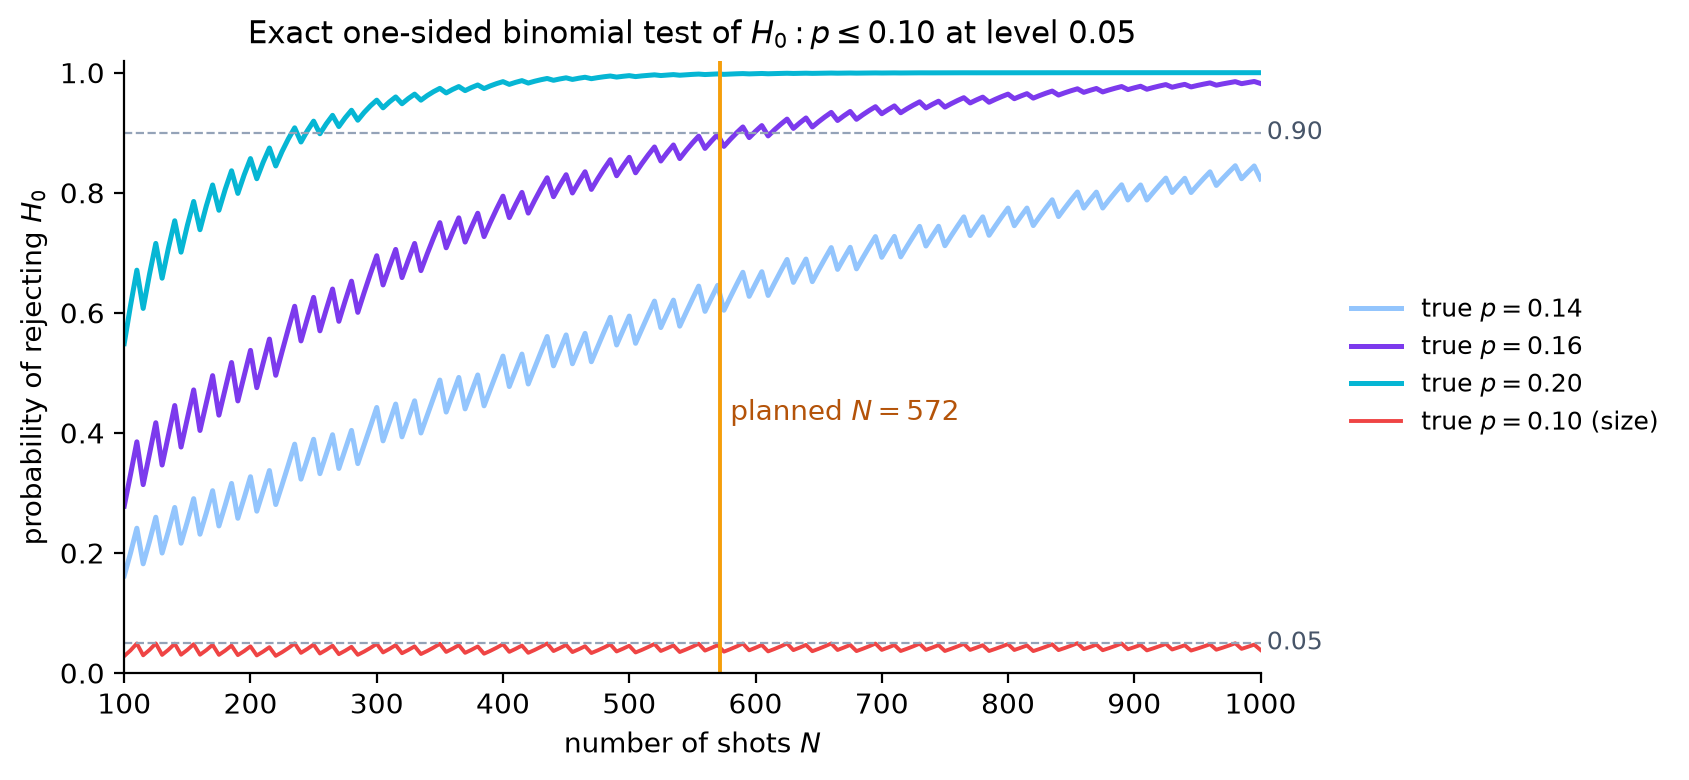

In [2]:
_show_mpl(_lessonfigs.power_curves())

*Exact power of the one-sided binomial test against the number of shots, for three true values of $p$, and its size at $p = 0.10$ (red). The sawtooth is binomial discreteness: power is not monotone in $N$, so the protocol fixes $N$ exactly rather than as a minimum.*

The estimator, the exact interval, the normal-approximation sample size, and the exact search that fixes $N$ and the critical count.


In [3]:
import math
import numpy as np
from scipy import stats

# Running example: E_p(rho) = (1 - p) rho + p I/2, input |0>, measure Z.  P(outcome 1) = q = p/2.
def estimate(k, n, alpha=0.05):
    q = k / n
    lo = stats.beta.ppf(alpha / 2, k, n - k + 1) if k > 0 else 0.0          # Clopper-Pearson for q
    hi = stats.beta.ppf(1 - alpha / 2, k + 1, n - k) if k < n else 1.0
    return 2 * q, 2 * math.sqrt(q * (1 - q) / n), (2 * lo, min(1.0, 2 * hi))

p_hat, se, ci = estimate(120, 1000)
print(f"120 ones in 1000 shots: p_hat = {p_hat:.2f}, plug-in SE = {se:.4f}, exact 95% CI for p = ({ci[0]:.3f}, {ci[1]:.3f})")

# Design: H0: p <= 0.10 (q0 = 0.05) against the planned alternative p1 = 0.16 (q1 = 0.08), level 0.05, power 0.90
q0, q1, alpha, power = 0.05, 0.08, 0.05, 0.90
za, zb = stats.norm.ppf(1 - alpha), stats.norm.ppf(power)
n_normal = ((za * math.sqrt(q0 * (1 - q0)) + zb * math.sqrt(q1 * (1 - q1))) / (q1 - q0)) ** 2

def k_star(n):                        # smallest k with P(K >= k | q0) <= alpha
    return int(stats.binom.isf(alpha, n, q0)) + 1

def exact_power(n, q):
    return stats.binom.sf(k_star(n) - 1, n, q)

n0 = math.ceil(n_normal)
print(f"normal approximation: N = {n_normal:.1f} -> {n0}; exact power there = {exact_power(n0, q1):.3f}")
n_plan = n0
while exact_power(n_plan, q1) < power:
    n_plan += 1
print(f"smallest N with exact power >= 0.90: N = {n_plan}, reject if K >= {k_star(n_plan)}, "
      f"exact size = {exact_power(n_plan, q0):.4f}, exact power = {exact_power(n_plan, q1):.3f}")
print("power is not monotone in N:", [round(float(exact_power(n, q1)), 3) for n in (606, 609, 612, 615)])

120 ones in 1000 shots: p_hat = 0.24, plug-in SE = 0.0206, exact 95% CI for p = (0.201, 0.284)
normal approximation: N = 554.1 -> 555; exact power there = 0.894
smallest N with exact power >= 0.90: N = 572, reject if K >= 38, exact size = 0.0484, exact power = 0.901
power is not monotone in N: [0.914, 0.893, 0.899, 0.905]


:::{prf:remark} Where the planned alternative comes from
:label: rem-l7-09-alt
The alternative $p_1 = 0.16$ is a scientific choice (the smallest deviation that matters), not an estimate from the data to be analyzed. Choosing it from the confirmatory data, or from a pilot that is then reused, makes the power statement circular.
:::

## Stopping rules: what peeking does

Now suppose the experimenter looks at the data after every batch and stops as soon as a test at level 0.05 rejects. To see the effect cleanly, use the normal limit: under $H_0$ the standardized statistic after $n$ shots behaves like $Z_n = W_n/\sqrt n$ for a Gaussian random walk $W_n$ with unit-variance steps.

:::{figure} ../../_static/animations/l7_09_optional_stopping.mp4
:alt: Forty jagged z-statistic paths grow from left to right; those that touch the dashed line at 1.645 turn red and stop. A counter reaches 11 of 40. Then bars show the exact false-positive rate rising with the number of looks.
:width: 100%

Forty seeded runs with $H_0$ true. Monitoring after every 10 shots stops 11 of 40 runs as significant; a single look at the planned end rejects 2 of 40. The bars give the exact rate for $K$ looks.
:::

:::{dropdown} What the animation shows
The horizontal axis is the number of shots, up to 1000, and the vertical axis the z-statistic $Z_n$. A dashed red line marks $z = 1.645$, the one-sided 5% threshold. Forty runs, all with the true parameter at the null value $p = 0.10$, grow from left to right, one point every 10 shots. A run that touches the line turns red and stops, and a counter of runs stopped as significant climbs during the sweep: in the end 11 of 40 runs crossed at some look. A vertical line at $n = 1000$ then shows that a single look at the planned end rejects only 2 of 40. These 40 paths use the normal-approximation statistic on binomial counts from the first 10 shots, where two outcomes 1 already exceed the threshold, so most of their early stops mix the peeking effect with small-sample discreteness. Finally a bar chart shows the exact false-positive rate for $K$ equally spaced looks of a Gaussian random walk: 0.050 for one look, 0.130 for 5, 0.215 for 20 and 0.311 for 100.
:::

:::{prf:proposition} The joint law of the interim statistics
:label: prop-l7-09-joint
Let $W_j = \xi_1 + \dots + \xi_j$ with independent standard normal $\xi_i$ and $Z_j = W_j/\sqrt j$. Then $(Z_1, \dots, Z_K)$ is jointly normal with unit variances and $\operatorname{corr}(Z_i, Z_j) = \sqrt{i/j}$ for $i \le j$. Testing at each look with critical value $c$ has false-positive rate
:::

$$
\mathrm{FPR}_K(c) = 1 - P\big(Z_1 \le c,\ Z_2 \le c,\ \dots,\ Z_K \le c\big) \;\ge\; 1 - \Phi(c)
$$ (eq-l7-09-fpr)

:::{prf:proof}
$(W_1, \dots, W_K)$ is a linear image of the Gaussian vector $(\xi_1, \dots, \xi_K)$, hence jointly normal, and $\operatorname{Cov}(W_i, W_j) = \sum_{k \le i} \operatorname{Var}\xi_k = i$ for $i \le j$. So $\operatorname{corr}(Z_i, Z_j) = i/\sqrt{ij} = \sqrt{i/j}$. The event of a false positive is the union of the events $\{Z_j > c\}$; its complement is the intersection of $\{Z_j \le c\}$, which gives the formula, and the union contains $\{Z_K > c\}$, which gives the bound. For $K \ge 2$ the inequality is strict: $(Z_1, Z_K)$ has correlation below 1, so its normal law has a positive density and $P(Z_1 > c \ge Z_K) > 0$.
:::

The inflation of the false-positive rate by repeated looks at accumulating data was quantified by Armitage, McPherson and Rowe for repeated two-sided tests on normal observations [@armitage1969]. For the one-sided test with $c = 1.645$ the exact rates, computed by recursive numerical integration in the code below, are 0.080 for 2 looks, 0.130 for 5, 0.172 for 10, 0.215 for 20, 0.270 for 50 and 0.311 for 100. The growth is slow but never stops:

:::{prf:theorem} Continuous monitoring rejects a true null with probability one
:label: thm-l7-09-sure
Let $X_1, X_2, \dots$ be independent and identically distributed with mean 0 and variance $\sigma^2 \in (0, \infty)$, $S_n = X_1 + \dots + X_n$, and $c$ any real number. Then $P\big(S_n/(\sigma\sqrt n) > c \text{ for some } n\big) = 1$.
:::

:::{prf:proof}
Let $A_n = \{S_n/(\sigma\sqrt n) > c\}$ and $E = \limsup_n A_n$, the event that $A_n$ happens infinitely often. By the reverse Fatou lemma, $P(E) \ge \limsup_n P(A_n)$, and by the central limit theorem $P(A_n) \to 1 - \Phi(c) > 0$. So $P(E) > 0$. Permuting finitely many of the $X_i$ leaves $S_n$ unchanged for all large $n$, so $E$ is invariant under finite permutations, and the Hewitt-Savage zero-one law gives $P(E) \in \{0, 1\}$. Hence $P(E) = 1$, and $E$ is contained in the event of the theorem.
:::


In [4]:
_show(_lessonfigs.peeking_explorer())

**Explore.** Seeded simulation of the running example with exact binomial p-values at each look. Move the slider from the null value $p = 0.10$ to alternatives and compare three stopping rules.

:::{dropdown} What the figure shows
The first panel plots the probability of rejecting $H_0: p \le 0.10$ against the number of equally spaced looks $K$ (1, 2, 4, 5, 10, 20) within a budget of 1000 shots, for three rules: test at level 0.05 at every look, Bonferroni at level $0.05/K$ per look, and stop when the likelihood ratio reaches 20. The second panel plots the mean number of shots used. At $p = 0.10$ the first rule's rejection rate climbs from 0.038 (one look; below 0.05 because the binomial test is discrete) to 0.176 at 20 looks, while the other two stay below 0.05 (0.012 and 0.028 at 20 looks). At $p = 0.16$, with 20 looks, Bonferroni has power 0.899 using 520 shots on average and the likelihood-ratio rule has power 0.928 using 431 shots. Each point is an average of 20,000 seeded runs.
:::

## Three valid ways to stop

The first valid design is the one already planned: a fixed $N$ and a single test. If interim looks are wanted (to stop early for a large effect, or for safety of an expensive device), the level must be paid for. Two ways can be proved in a few lines.

:::{prf:proposition} Alpha spending by the union bound
:label: prop-l7-09-spending
Let $\pi_1, \dots, \pi_K$ be valid p-values computed at the $K$ looks, meaning $P_{H_0}(\pi_j \le u) \le u$ for all $u \in [0, 1]$, and let $\alpha_1, \dots, \alpha_K \ge 0$ be fixed in the protocol with $\sum_j \alpha_j \le \alpha$. The rule that rejects at the first look with $\pi_j \le \alpha_j$ has false-positive rate at most $\alpha$, whatever the dependence between looks. Bonferroni is $\alpha_j = \alpha/K$.
:::

:::{prf:proof}
$P_{H_0}\big(\bigcup_j \{\pi_j \le \alpha_j\}\big) \le \sum_j P_{H_0}(\pi_j \le \alpha_j) \le \sum_j \alpha_j \le \alpha$. Exact binomial p-values satisfy the validity condition at every sample size, so the bound holds without any normal approximation.
:::

The union bound ignores the strong positive correlation $\sqrt{i/j}$ between looks, so it is conservative: in the Gaussian model the actual rate of Bonferroni is 0.042 for 2 looks, 0.031 for 5, 0.024 for 10 and 0.017 for 20. Boundaries that use the correlation exactly can be computed numerically from [](#eq-l7-09-fpr) and spend the level more efficiently; the spending-function approach of Lan and DeMets fixes in advance how much of $\alpha$ may be used by each fraction of the planned information, so that the number and timing of the looks need not be fixed [@lan1983]. Either way, the protocol must name the boundary before the data. The second approach removes the need to fix the looks at all; it rests on an inequality proved by Jean Ville in 1939.

:::{prf:theorem} Ville's inequality
:label: thm-l7-09-ville
Let $(L_n)_{n \ge 0}$ be a nonnegative supermartingale with $L_0 = 1$. Then for every $\alpha \in (0, 1)$, $P\big(\sup_{n} L_n \ge 1/\alpha\big) \le \alpha$.
:::

:::{prf:proof}
Let $\tau$ be the first $n$ with $L_n \ge 1/\alpha$ ($\tau = \infty$ if there is none) and fix $N$. The stopped time $\tau \wedge N$ is bounded, so optional stopping for supermartingales gives $\mathbb{E}[L_{\tau \wedge N}] \le L_0 = 1$. On the event $\{\tau \le N\}$ we have $L_{\tau \wedge N} = L_\tau \ge 1/\alpha$, and $L \ge 0$ elsewhere, so $\mathbb{E}[L_{\tau \wedge N}] \ge P(\tau \le N)/\alpha$. Together, $P(\tau \le N) \le \alpha$. The events $\{\tau \le N\}$ increase to $\{\tau < \infty\} = \{\sup_n L_n \ge 1/\alpha\}$, and continuity of probability gives the claim.
:::

For the running example take the likelihood ratio of the planned alternative $q_1 = 0.08$ against $q_0 = 0.05$ after outcomes $x_1, \dots, x_n$:

$$
L_n = \prod_{i=1}^{n}\Big(\frac{q_1}{q_0}\Big)^{x_i}\Big(\frac{1-q_1}{1-q_0}\Big)^{1-x_i}, \qquad \mathbb{E}_q\Big[\frac{L_{n+1}}{L_n}\,\Big|\,x_{1:n}\Big] = 1 + \frac{(q - q_0)(q_1 - q_0)}{q_0(1 - q_0)}
$$ (eq-l7-09-lr)

For every true $q \le q_0$ the conditional mean factor is at most 1 because $q_1 > q_0$, so $L_n$ is a nonnegative supermartingale with $L_0 = 1$ under the whole composite null $H_0: p \le 0.10$. By Ville's inequality the rule *reject as soon as $L_n \ge 20$* has false-positive rate at most $1/20 = 0.05$, however often one looks and whenever one stops.

:::{figure} ../../_static/animations/l7_09_ville_barrier.mp4
:alt: Forty log-likelihood-ratio paths drift downward under the null, one touches the dashed barrier log 20, and a four-line derivation of Ville's inequality transforms line by line.
:width: 100%

Under $H_0$ the likelihood ratio is a nonnegative supermartingale and drifts down; the barrier $20 = 1/\alpha$ is reached with probability at most 0.05, so the rule can be checked after every shot.
:::

:::{dropdown} What the animation shows
Forty seeded runs with $H_0$ true show $\log L_n$ against the number of shots, for $q_0 = 0.05$ and $q_1 = 0.08$. The paths drift downward, because under the null the expected log-likelihood ratio decreases at each shot. A dashed red line marks $\log 20$. Only 1 of 40 runs reaches it. The derivation then transforms line by line: $\mathbb{E}[L_{\tau \wedge N}] \le L_0 = 1$ by optional stopping; $\mathbb{E}[L_{\tau \wedge N}] \ge 20\,P(\tau \le N)$ because the stopped value is at least 20 on that event; so $P(\tau \le N) \le 1/20$; and letting $N$ grow, $P(\sup_n L_n \ge 20) \le 0.05$, valid at every $n$ at once.
:::

Exact Gaussian false-positive rates for $K$ looks, and the Bernoulli simulation behind the explorer at 20 looks: the peeking rule, Bonferroni, and the likelihood-ratio rule.


In [5]:
import math
import numpy as np
from scipy import stats
from scipy.signal import fftconvolve

c = stats.norm.ppf(0.95)              # one-sided level 0.05

def gauss_fpr(K, c=c, h=0.004):
    """P(Z_j > c for some j <= K): Gaussian walk W_j, Z_j = W_j / sqrt(j), recursive numerical integration."""
    x = np.arange(-9 * math.sqrt(K), c * math.sqrt(K) + h, h)
    kx = np.arange(-9, 9 + h / 2, h)
    ker = stats.norm.pdf(kx) * h
    f = np.where(x <= c, stats.norm.pdf(x), 0.0)
    for j in range(2, K + 1):
        f = fftconvolve(f, ker)[len(kx) // 2: len(kx) // 2 + len(x)]
        f = np.where(x <= c * math.sqrt(j), f, 0.0)
    return 1 - f.sum() * h

for K in (2, 5, 10, 20):
    print(f"K = {K:2d} looks: naive {gauss_fpr(K):.3f}   Bonferroni {gauss_fpr(K, stats.norm.ppf(1 - 0.05 / K)):.3f}")

# Bernoulli version of the running example: 20 looks, one every 50 shots, H0 true (p = 0.10, q0 = 0.05)
q0, q1, m = 0.05, 0.08, 20000
rng = np.random.default_rng([2026, 100])
counts = rng.binomial(50, q0, size=(m, 20)).cumsum(axis=1)      # outcome-1 counts at each look
n = 50 * np.arange(1, 21)
pval = stats.binom.sf(counts - 1, n, q0)                        # exact one-sided p-value at each look
loglr = counts * math.log(q1 / q0) + (n - counts) * math.log((1 - q1) / (1 - q0))
rates = {"peek at 0.05": (pval <= 0.05).any(axis=1).mean(),
         "Bonferroni 0.05/20": (pval <= 0.05 / 20).any(axis=1).mean(),
         "likelihood ratio >= 20": (loglr >= math.log(20)).any(axis=1).mean()}
for k, v in rates.items():
    print(f"{k:24s} false-positive rate {v:.3f}  (Monte Carlo SE {math.sqrt(v * (1 - v) / m):.4f})")

K =  2 looks: naive 0.080   Bonferroni 0.042
K =  5 looks: naive 0.130   Bonferroni 0.031
K = 10 looks: naive 0.172   Bonferroni 0.024
K = 20 looks: naive 0.215   Bonferroni 0.017
peek at 0.05             false-positive rate 0.176  (Monte Carlo SE 0.0027)
Bonferroni 0.05/20       false-positive rate 0.012  (Monte Carlo SE 0.0008)
likelihood ratio >= 20   false-positive rate 0.028  (Monte Carlo SE 0.0012)


With 20 looks and $H_0$ true the simulation gives false-positive rates 0.176 for peeking (Monte Carlo standard error 0.0027), 0.012 for Bonferroni and 0.028 for the likelihood ratio, from 20,000 seeded runs. Under the alternative $p = 0.16$ the two valid rules reach power 0.899 and 0.928 using on average 520 and 431 of the 1000 shots, compared with power 0.901 for the fixed design at 572 shots.

:::{warning} Sequential designs save shots only when there is something to find
When $H_0$ is true the likelihood-ratio rule rarely stops early: it used on average 982 shots out of the budget of 1000, far more than the fixed design's 572. Its power also depends on how close the true $p$ is to the planned $p_1$. A sequential design is a trade, and the protocol should state which case it optimizes.
:::

## A worked mini-study: two qubits and a latent bit

Now a causal question in the sense of [L4-06](#lesson-l4-06), with interventions as in [L6-04](#lesson-l6-04) and quantum causal models [@costa]. Qubit $B$ starts in $|0\rangle$. A latent classical bit $H$ (fair coin) flips $B$ to $|1\rangle$ with probability $c = 0.30$ when $H = 1$. Qubit $A$ then interacts with $B$ through the partial swap $U_\theta = \exp(-i\theta(X \otimes X + Y \otimes Y)/2)$, and $B$ is measured in the $Z$ basis. In the **observational** regime $A$ is prepared in $|h\rangle$, a copy of the latent bit, so $H$ is a common cause of $A$ and $B$. In the **interventional** regime the experimenter prepares $A$ in $|a\rangle$ with $a$ chosen by a fair coin, independent of $H$: this is $do(a)$. Everything below is a simulation of this model, not an experiment.

:::{prf:proposition} What each regime identifies
:label: prop-l7-09-ace
Let $s = \sin^2\theta$. Then $P(B{=}1 \mid do(1)) = \tfrac c2 + (1 - \tfrac c2)s$ and $P(B{=}1 \mid do(0)) = \tfrac c2(1-s)$, so the average causal effect is $\mathrm{ACE} = s$, whatever $c$ is. In the observational regime $P(B{=}1 \mid A{=}1) - P(B{=}1 \mid A{=}0) = s + c(1-s)$, which exceeds the ACE by the confounding bias $c(1-s)$.
:::

:::{prf:proof}
On the subspace spanned by $|01\rangle, |10\rangle$, $X \otimes X + Y \otimes Y$ acts as $2\sigma_x$, and it annihilates $|00\rangle$ and $|11\rangle$. So $U_\theta$ fixes $|00\rangle$ and $|11\rangle$ and maps $|10\rangle \mapsto \cos\theta|10\rangle - i\sin\theta|01\rangle$, $|01\rangle \mapsto \cos\theta|01\rangle - i\sin\theta|10\rangle$. Writing $b_0$ for the state of $B$ before the swap, $P(B{=}1 \mid a, b_0)$ is 0 for $(0,0)$, 1 for $(1,1)$, $s$ for $(1,0)$ and $1-s$ for $(0,1)$. Given $h$, $b_0 = 1$ with probability $ch$. With $a$ independent of $h$, average over $h \in \{0, 1\}$: $P(B{=}1 \mid do(1)) = \tfrac12 s + \tfrac12[c + (1-c)s] = \tfrac c2 + (1 - \tfrac c2)s$ and $P(B{=}1 \mid do(0)) = \tfrac12 \cdot 0 + \tfrac12 c(1-s)$. Subtracting gives $s$. Observationally $a = h$, so $P(B{=}1 \mid A{=}1) = c + (1-c)s$ and $P(B{=}1 \mid A{=}0) = 0$; the difference is $s + c(1-s)$.
:::

:::{figure} ../../_static/animations/l7_09_mini_study.mp4
:alt: A three-wire circuit with a dashed latent wire H, an intervention box do(a) on A, a flip box c on B controlled by H, a partial-swap box theta, and a Z measurement on B; then the effect derivation and two running estimates converging to different values.
:width: 100%

The protocol run on a simulated causal model. Randomizing $a$ identifies $\mathrm{ACE} = s = 0.10$; copying the latent bit gives the confounded contrast $s + c(1-s) = 0.37$.
:::

:::{dropdown} What the animation shows
The circuit has three wires: a dashed latent wire $H$, and qubits $A$ and $B$. A box $do(a)$ prepares $A$; a box labeled $c$ on $B$, controlled by $H$, flips $B$ with chance $c = 0.30$; a two-qubit box $\theta$ is the partial swap with $\sin^2\theta = s = 0.10$; $B$ is measured in $Z$. The derivation transforms $P(B{=}1 \mid do(1)) - P(B{=}1 \mid do(0))$ into $[\tfrac c2 + (1 - \tfrac c2)s] - \tfrac c2(1-s)$ and then into $\mathrm{ACE} = s = 0.10$. If $A$ copies $H$ the contrast is $s + c(1-s) = 0.37$. Then two running estimates are drawn against the number of shots per arm, up to 257: the randomized estimate (violet) settles near the dashed line at 0.10 and the observational contrast (amber) near the dashed line at 0.37. The final values are a randomized estimate of 0.062 with one-sided 95% lower bound 0.008, above zero, and an observational contrast of 0.412, from 257 shots per arm with seed 909.
:::

:::{prf:algorithm} The mini-study protocol
:label: alg-l7-09-study
1. **Question.** Does preparing $A$ change the $Z$ outcome of $B$?  
2. **Estimand.** $\mathrm{ACE} = P(B{=}1 \mid do(1)) - P(B{=}1 \mid do(0))$.  
3. **Identification.** Randomizing $a$ makes it independent of $H$, so the arm means estimate the interventional probabilities [@pearlcausality; @hernan].  
4. **Design.** Two arms with equal shots, block randomized; $Z$ readout of $B$.  
5. **Sample size.** One-sided level 0.05, power 0.90 at $\mathrm{ACE} = 0.10$ with arm rates $0.135$ and $0.235$ assumed from a pilot: 257 shots per arm by the two-proportion formula.  
6. **Stopping rule.** Fixed: 514 shots, no interim looks; simulation seed 909 recorded in advance.  
7. **Analysis.** Difference of arm means, unpooled standard error, one-sided 95% lower bound; reject $H_0: \mathrm{ACE} \le 0$ if the pooled $z$ exceeds 1.645.  
8. **Robustness.** Readout error on $B$ (see below); the observational contrast is computed as a reported secondary quantity, not a test of the effect.  
9. **Report.** Counts per arm, all numbers below, the code, and the seed.
:::

The partial swap is built as a matrix, the four regime probabilities are computed from it, and the study is simulated exactly as preregistered.


In [6]:
import math
import numpy as np
from scipy import stats

s, c = 0.10, 0.30                      # sin^2(theta) of the partial swap; latent flip probability
th = math.asin(math.sqrt(s))
U = np.eye(4, dtype=complex)           # exp(-i theta (XX + YY)/2) on (A, B), basis |00>, |01>, |10>, |11>
U[1, 1] = U[2, 2] = math.cos(th)
U[1, 2] = U[2, 1] = -1j * math.sin(th)

def pb1(a, b0):                        # P(B = 1) after the swap acts on |a, b0>
    out = U @ np.eye(4)[2 * a + b0]
    return abs(out[1]) ** 2 + abs(out[3]) ** 2

def rate(a, h):                        # the latent bit h = 1 flips B (to |1>) with probability c
    return c * h * pb1(a, 1) + (1 - c * h) * pb1(a, 0)

do0 = 0.5 * rate(0, 0) + 0.5 * rate(0, 1)
do1 = 0.5 * rate(1, 0) + 0.5 * rate(1, 1)
obs0, obs1 = rate(0, 0), rate(1, 1)    # observational regime: A copies H
print(f"P(B=1|do(0)) = {do0:.3f}, P(B=1|do(1)) = {do1:.3f}, ACE = {do1 - do0:.3f}")
print(f"observational contrast P(B=1|A=1) - P(B=1|A=0) = {obs1 - obs0:.3f} = s + c(1-s) = {s + c * (1 - s):.3f}")

# preregistered design: one-sided level 0.05, power 0.90 at ACE = 0.10, equal arms
za, zb = stats.norm.ppf(0.95), stats.norm.ppf(0.90)
rbar = (do0 + do1) / 2
n_arm = math.ceil(((za * math.sqrt(2 * rbar * (1 - rbar)) + zb * math.sqrt(do0 * (1 - do0) + do1 * (1 - do1)))
                   / (do1 - do0)) ** 2)
print("shots per arm:", n_arm)

rng = np.random.default_rng(909)       # the seed is part of the protocol
y0 = rng.random(n_arm) < do0
y1 = rng.random(n_arm) < do1
h = rng.random(2 * n_arm) < 0.5
yo = rng.random(2 * n_arm) < np.where(h, obs1, obs0)
ace_hat = y1.mean() - y0.mean()
se = math.sqrt(y0.mean() * (1 - y0.mean()) / n_arm + y1.mean() * (1 - y1.mean()) / n_arm)
pool = (y0.sum() + y1.sum()) / (2 * n_arm)
z = ace_hat / math.sqrt(pool * (1 - pool) * 2 / n_arm)
print(f"arm counts {y0.sum()}/{n_arm} and {y1.sum()}/{n_arm}: ACE_hat = {ace_hat:.3f} (SE {se:.3f}), "
      f"one-sided 95% lower bound {ace_hat - za * se:.3f}, pooled z = {z:.2f}, reject H0: {z > za}")
print(f"observational contrast from {2 * n_arm} shots: {yo[h].mean() - yo[~h].mean():.3f}")

P(B=1|do(0)) = 0.135, P(B=1|do(1)) = 0.235, ACE = 0.100
observational contrast P(B=1|A=1) - P(B=1|A=0) = 0.370 = s + c(1-s) = 0.370
shots per arm: 257
arm counts 36/257 and 52/257: ACE_hat = 0.062 (SE 0.033), one-sided 95% lower bound 0.008, pooled z = 1.87, reject H0: True
observational contrast from 514 shots: 0.412


The arms recorded 36 and 52 outcomes 1 out of 257 each, rates 0.140 and 0.202. The estimate is $\widehat{\mathrm{ACE}} = 0.062$ with standard error 0.033, so the one-sided 95% lower bound is 0.008; the pooled statistic $z = 1.87 > 1.645$, and the plan's decision is to reject $H_0: \mathrm{ACE} \le 0$. The estimate is below the true value 0.10; that is ordinary sampling variation, and the report gives it as observed. The observational contrast from the same number of shots is 0.412, near its population value 0.37. The pooled $z$-test is asymptotic, so its level was checked by simulation at the null point $s = 0$ with the same $c$: rejection rate 0.048 in 20,000 seeded replications (standard error about 0.0015), and power 0.903 at $s = 0.10$.

:::{prf:proposition} Readout error cannot fake this effect
:label: prop-l7-09-attenuate
If $B$'s outcome is flipped with probability $\varepsilon < 1/2$ independently of everything else, the arm means converge to $\varepsilon + (1 - 2\varepsilon)P(B{=}1 \mid do(a))$, so the estimated contrast converges to $(1 - 2\varepsilon)\,\mathrm{ACE}$.
:::

:::{prf:proof}
The flip acts as in [](#lem-l7-09-readout) in each arm: an observed 1 has probability $\varepsilon + (1-2\varepsilon)r_a$ where $r_a$ is the true rate in arm $a$. The difference of the two arms is $(1-2\varepsilon)(r_1 - r_0)$. In particular it is zero exactly when the ACE is zero, so symmetric readout noise can lower the power but cannot create a false positive; it does bias the estimate toward zero, which the report must say if $\varepsilon$ was not calibrated.
:::

## Writing the result

A report has three registers, and mixing them is the commonest overclaim. **Established** (under the stated model and assumptions): the theorems used, here the estimator's unbiasedness, the identification of the ACE by randomization, and the validity of the test. **Numerical evidence**: what this run or simulation showed, with its uncertainty: $\widehat{\mathrm{ACE}} = 0.062$, lower bound 0.008, from a simulation with seed 909. **Interpretation**: what the authors believe it means beyond that, for example that a real device with this architecture would show a similar effect, which is a hypothesis for the next protocol.

:::{tip} A negative result is a result
If the plan does not reject, report the interval: it bounds the effect. A failure to identify (as in [](#lem-l7-09-readout)) or a cost left out of an earlier comparison ([L7-06](#lesson-l7-06)) are contributions. Keep every attempt, including failed runs, in the deviation log; benchmarks that drop failures cannot be reproduced ([L7-08](#lesson-l7-08)).
:::

:::{prf:remark} What a simulation can and cannot establish
:label: rem-l7-09-sim
A simulation checks that the protocol does what the mathematics says (here, that the test holds its level and reaches its power) and estimates quantities that are hard to compute in closed form. It does not show that a device obeys the model. Statements about hardware need hardware data analyzed by a protocol written before those data existed.
:::

## Worked example

:::{admonition} Running the preregistered depolarizing test
:class: tip

The protocol fixed $N = 572$ shots, input $|0\rangle$, $Z$ measurement, and the rule: reject $H_0: p \le 0.10$ if $K \ge 38$, then report $\hat p$ with the exact 95% interval. The run records $K = 41$ ones. Carry out the analysis plan and write the conclusion in the three registers.

1. Decision: $41 \ge 38$, so the plan rejects $H_0$ at level 0.05. The exact one-sided p-value is $P(K \ge 41 \mid N = 572, q = 0.05) = 0.0146$; it is reported but does not change the decision rule.
2. Estimate: $\hat p = 2 \times 41/572 = 0.143$. The exact Clopper-Pearson interval for $q$, mapped through $p = 2q$, is $(0.104, 0.192)$ for $p$.
3. Assumptions to state: independent shots, the depolarizing model [](#eq-l7-09-model), trusted preparation of $|0\rangle$ and readout with $\varepsilon = 0$. By [](#lem-l7-09-readout), a readout flip probability of $\varepsilon$ would make $2K/N$ overestimate $p$ by exactly $2\varepsilon(1 - p)$ in expectation, so a calibration result belongs in the report.
4. Registers: established, the test has exact level at most 0.05 under the model; numerical evidence, $\hat p = 0.143$ with the interval above from 572 shots; interpretation, the device is probably above specification, conditional on the readout being calibrated.

**Result.** Reject $H_0$; $\hat p = 0.143$ with exact 95% interval $(0.104, 0.192)$, valid under the stated model and with trusted readout.
:::

## Exercises

**1. (Core)** With the same model, 800 shots give 80 outcomes 1. Estimate $p$ and its plug-in standard error. Name one residual pattern that would challenge the assumed depolarizing model.

:::{dropdown} Solution
$\hat q = 0.1$, so $\hat p = 0.2$ and the plug-in standard error is $2\sqrt{0.1 \times 0.9/800} = 0.0212$. Depolarizing noise contracts the Bloch vector equally in every direction. If calibrated $X$, $Y$ and $Z$ probes (prepare an eigenstate, measure in the same basis) show clearly different contraction factors, the noise is not isotropic, and a Pauli or amplitude-damping model is needed; $p$ is then not a complete description of the channel.
:::

**2. (Core)** A team plans three looks and uses Bonferroni. What per-look level does it use, and what is the guaranteed bound on its false-positive rate? What would the bound be for three independent unplanned analyses at 0.05 each?

:::{dropdown} Solution
Per-look level $0.05/3 \approx 0.0167$; by the union bound the false-positive rate is at most $3 \times 0.0167 = 0.05$. Three independent analyses each at 0.05 give $1 - 0.95^3 = 0.1426$ when every null is true.
:::

**3. (Stretch)** Derive the conditional mean factor in [](#eq-l7-09-lr) and show that $L_n$ is a supermartingale for every $q \le q_0$ but a submartingale (mean factor above 1) for $q > q_0$, when $q_1 > q_0$. Why does this make the rule *reject when $L_n \ge 20$* both valid and powerful?

:::{dropdown} Solution
$\mathbb{E}_q[L_{n+1}/L_n] = q\,\frac{q_1}{q_0} + (1-q)\frac{1-q_1}{1-q_0}$. At $q = q_0$ this is $q_1 + 1 - q_1 = 1$. It is linear in $q$ with slope $\frac{q_1}{q_0} - \frac{1-q_1}{1-q_0} = \frac{q_1 - q_0}{q_0(1-q_0)}$, which gives $1 + \frac{(q-q_0)(q_1-q_0)}{q_0(1-q_0)}$. With $q_1 > q_0$ the factor is at most 1 for $q \le q_0$ (supermartingale, so Ville's inequality bounds the false-positive rate by 0.05 over the whole null) and above 1 for $q > q_0$, so under the alternative $L_n$ tends to grow (its logarithm has positive drift when $q$ is near $q_1$) and eventually crosses 20.
:::

**4. (Stretch)** In the readout model of [](#lem-l7-09-readout), a calibration arm gives $\varepsilon = 0.025$ and the channel arm gives $P(1) = 0.12$. Find $p$. What would an analyst who ignored readout error report?

:::{dropdown} Solution
$P(1) = \varepsilon + (1 - 2\varepsilon)p/2$, so $p = 2(P(1) - \varepsilon)/(1 - 2\varepsilon) = 2 \times 0.095/0.95 = 0.20$. Ignoring readout error gives $\hat p = 2 \times 0.12 = 0.24$, an overestimate by 0.04.
:::

**5. (Challenge)** For $K = 2$ looks at $n$ and $2n$ shots in the Gaussian model, write the false-positive rate of the peeking rule with $c = 1.645$ as a bivariate normal probability and evaluate it. Then find the common critical value $c_2$ that makes the two-look rule exactly level 0.05 (numerically), and compare with Bonferroni's $z_{1 - 0.025} = 1.960$.

:::{dropdown} Solution
By [](#prop-l7-09-joint), $(Z_1, Z_2)$ is standard bivariate normal with correlation $\sqrt{1/2} \approx 0.707$, so $\mathrm{FPR}_2 = 1 - \Phi_2(1.645, 1.645; 0.707) \approx 1 - 0.920 = 0.080$. Solving $1 - \Phi_2(c_2, c_2; 0.707) = 0.05$ numerically (for example by bisection with `scipy.stats.multivariate_normal`) gives $c_2 \approx 1.875$. It lies between 1.645 and Bonferroni's 1.960: using the correlation buys back part of the level that the union bound wastes (Bonferroni's actual rate here is 0.042).
:::

**6. (Challenge)** In the mini-study, for which latent flip probability $c$ is the observational contrast exactly twice the ACE when $s = 0.10$? Show that no value of $c \in [0, 1]$ makes the observational contrast smaller than the ACE, and explain what model change could make the confounding bias negative.

:::{dropdown} Solution
By [](#prop-l7-09-ace) the contrast is $s + c(1-s)$, and $s + c(1-s) = 2s$ gives $c = s/(1-s) = 0.1/0.9 \approx 0.111$. Since $c(1-s) \ge 0$ for $c \in [0,1]$ and $s \le 1$, the contrast is never below $s$. The bias is positive because the latent bit pushes $A$ and $B$ toward the same value. If $H = 1$ instead set $A$ to $|0\rangle$ while flipping $B$ (an anti-correlating common cause), the observational contrast would be $P(B{=}1 \mid A{=}1) - P(B{=}1 \mid A{=}0) = s - c(1-s)$ (the arm with $A = 0$ now carries the latent flips), so confounding could even hide or reverse the effect.
:::

## Check your understanding

**1. A group computes an exact p-value after every batch and stops at the first $p \le 0.05$. Why is the reported level wrong?**

- **A.** Stopping early always lowers power
- **B.** The estimator becomes biased only under the alternative
- **C.** Exact p-values are invalid for small batches
- **D.** The false-positive rate is the probability that any of the looks rejects, which exceeds 0.05 and tends to 1 with unlimited looks

:::{dropdown} Show the answer
**D. The false-positive rate is the probability that any of the looks rejects, which exceeds 0.05 and tends to 1 with unlimited looks**

Each look is a valid level-0.05 test, but the procedure rejects if any look rejects. By [](#eq-l7-09-fpr) that probability is larger than 0.05 (0.215 for 20 Gaussian looks), and by [](#thm-l7-09-sure) it tends to 1 under continuous monitoring.
:::

**2. A protocol uses a likelihood ratio $L_n$ that is a nonnegative supermartingale with $L_0 = 1$ under $H_0$, and wants an anytime-valid test at level 0.01. What threshold does Ville's inequality give?**

- **A.** Reject when $L_n \ge 0.99$
- **B.** Reject when $L_n \ge 2.326$
- **C.** Reject when $\log L_n \ge 0.01$
- **D.** Reject when $L_n \ge 100$

:::{dropdown} Show the answer
**D. Reject when $L_n \ge 100$**

Ville's inequality gives $P(\sup_n L_n \ge 1/\alpha) \le \alpha$, so $1/\alpha = 100$. The value 2.326 is a normal quantile, which belongs to a fixed-sample z-test.
:::

**3. In the mini-study, $B$'s readout flips with probability $\varepsilon = 0.02$ in both arms. What happens to the test of $H_0: \mathrm{ACE} \le 0$?**

- **A.** The ACE is no longer identified even with randomization
- **B.** It produces false positives at rate $\varepsilon$
- **C.** The observational contrast becomes unbiased
- **D.** Its level is unaffected and the contrast shrinks by the factor $0.96$, so power falls slightly

:::{dropdown} Show the answer
**D. Its level is unaffected and the contrast shrinks by the factor $0.96$, so power falls slightly**

By [](#prop-l7-09-attenuate) the arm difference converges to $(1 - 2\varepsilon)\mathrm{ACE} = 0.96\,\mathrm{ACE}$; it is zero exactly when the ACE is zero, so no false positives are created, and the estimate is biased toward zero.
:::

**4. A target $T$ is identifiable from the data map $D$ over a model class when:** *(Review of [L7-05](#lesson-l7-05))*

- **A.** Some estimator of $T$ has small variance
- **B.** The data map is linear
- **C.** $T(M_1) = T(M_2)$ whenever $D(M_1) = D(M_2)$ for models in the class
- **D.** $T$ can be computed from the model's parameters

:::{dropdown} Show the answer
**C. $T(M_1) = T(M_2)$ whenever $D(M_1) = D(M_2)$ for models in the class**

Identifiability means the target is a function of the data distribution: models that produce the same data must agree on the target. The readout lemma of this lesson is a failure of exactly this condition.
:::

## Common misconceptions

- **"Peeking a few times only changes the level a little, so a p-value of 0.03 after peeking is still fine."** Five looks already move the Gaussian false-positive rate from 0.05 to 0.130, and the rate keeps growing toward 1 with more looks. Without the stopping rule, a reported p-value has no definite meaning.
- **"A sequential design always needs fewer shots than a fixed design."** Only when the alternative is true and close to the planned one. In this lesson's simulation the likelihood-ratio rule used about 431 shots under $p = 0.16$ but about 982 under $H_0$, compared with 572 for the fixed design.
- **"Preregistration means no exploratory analysis is allowed."** It means exploratory analyses are labeled as such and not used as confirmatory evidence. They are often the source of the next protocol's question.
- **"A simulation that confirms the hypothesis is evidence about the device."** A simulation shows what the model implies and whether the protocol holds its error rates. Evidence about a device needs data from the device, analyzed by a plan fixed before those data.

:::{caution} Scope and limits
The running example assumes independent shots, the depolarizing convention [](#eq-l7-09-model), and trusted preparation and readout; bias in those operations biases $\hat p$, and the protocol must state how it is handled. The 40 illustrative paths in the optional-stopping animation use a normal-approximation statistic from 10 shots onward, so their early crossings also reflect small-sample discreteness; the rates quoted in the text come from the exact Gaussian computation and the exact-p-value simulation. The Gaussian results for interim looks are the normal limit of the binomial test, not exact binomial statements; the binomial rates in the explorer and code are Monte Carlo estimates from 20,000 seeded runs, with standard errors of at most about 0.003. The mini-study is a simulated toy model chosen so that the effect is identified by randomization; it is not a model of any particular device, and its pooled $z$-test is asymptotic, with its level checked only at the null point $s = 0$, $c = 0.30$. Group sequential boundaries that use the exact correlation [@lan1983], and time-uniform confidence sequences [@howard2021], refine the two valid rules proved here; they are not developed in this lesson.
:::

:::{seealso} Where this leads
The protocol stations reuse earlier lessons: identification before learning in [L7-05](#lesson-l7-05), resource accounting and sample complexity in [L7-06](#lesson-l7-06), and reproducible benchmarks in [L7-08](#lesson-l7-08). The next lesson, [L7-10](#lesson-l7-10), applies the same discipline to reading the literature: a claim is audited by asking what protocol, if any, could have produced it.
:::

:::{dropdown} For instructors

**Why this lesson.** Doctoral students know individual tests well but often do not see that a stopping rule or an analysis choice is part of the test. Making the protocol a mathematical object with provable guarantees (union bound, Ville's inequality, identification by randomization) turns research hygiene into theorems they can apply [@hernan; @pearlcausality; @openstax_design].

**Teaching notes.**

- Start with the optional stopping animation before any formula; ask students to predict the fraction of runs that cross before revealing 11 of 40.
- Have students write a full nine-station protocol for a question from their own work, then exchange protocols and try to find a forking path the author left open.
- Contrast the three valid rules on the explorer: the slider at $p = 0.10$ shows validity, at $p = 0.16$ shows power and shots used; ask which design they would choose for an expensive device and why.
- In the mini-study, insist that the observational contrast is reported as a secondary quantity with its interpretation, not as a second test of the effect.

**Assessment.** The challenge exercise on the two-look boundary tests whether students can use the joint law of interim statistics; the written protocol (teaching note 2) is the main assessment, graded on whether every station is specific enough that another group could run the study without asking a question.

**Going further.** Replace the fixed-alternative likelihood ratio by a mixture over $q_1$ (still a nonnegative martingale under $q_0$, hence still valid by Ville's inequality) and compare its power across alternatives in simulation. Add a calibration arm for readout error to the mini-study and redo the sample size for the joint design.

:::

## References

This lesson draws on [@hernan; @pearlcausality; @openstax_design; @nielsenchuang; @costa; @armitage1969; @lan1983; @howard2021].

**Further reading.**

- [@bareinboim]: Identification as a precondition for estimation, developed in full for structural causal models.
- [@hernan]: Randomization, identification conditions and the separation of design from analysis in causal studies.

**Next:** [L7-10 · Open problems and critical synthesis](#lesson-l7-10)
